# Stories Coffee: Exploratory Data Analysis

**Goal of this notebook:** check data quality, describe the business as the data shows it, and rank candidate business problems by value and strength of evidence. The headline analysis is in later notebooks.

**Data:** `stories_transactions.csv`, one row per line item, 3 branches, 1 Jan to 30 Jun 2026.

Throughout, **observed facts** (computed from the data) are kept separate from **assumptions** (marked *Assumption*) and **estimates** (marked *Estimate*).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
# Repository layout: run from the repo root or notebooks/; data comes from STORIES_DATA or data/
ROOT = Path.cwd()
if not (ROOT / "reports").exists(): ROOT = ROOT.parent
DATA = Path(os.environ.get("STORIES_DATA", ROOT / "data" / "stories_transactions.csv"))
FIG = ROOT / "figures" / "eda"; FIG.mkdir(parents=True, exist_ok=True)

# One fixed colour per branch, used in every chart (validated categorical slots 1-3)
BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "font.size": 9, "legend.frameon": False, "lines.linewidth": 2,
})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

## 1. Load and data quality

In [2]:
raw = pd.read_csv(DATA, dtype={"Customer ID": "string"})
raw = raw.rename(columns={
    "Transaction ID": "txn", "Date": "date", "Time": "time", "Branch": "branch",
    "Customer ID": "cust", "Order Type": "order_type", "Product": "product",
    "Category": "category", "Quantity": "qty", "Unit Price (USD)": "price",
    "Discount Rate": "disc", "Unit Cost (USD)": "cost",
    "Line Revenue (USD)": "rev", "Line Gross Profit (USD)": "gp"})
raw["ts"] = pd.to_datetime(raw["date"] + " " + raw["time"])
raw["date"] = pd.to_datetime(raw["date"])
print(raw.shape)
print("transactions:", raw.txn.nunique(), "| products:", raw["product"].nunique(),
      "| known customers:", raw.cust.nunique())
print("dates:", raw.date.min().date(), "to", raw.date.max().date(),
      "| distinct days:", raw.date.nunique(), "of", (raw.date.max() - raw.date.min()).days + 1)
raw.isna().sum()

(51177, 15)
transactions: 33887 | products: 45 | known customers: 3494
dates: 2026-01-01 to 2026-06-30 | distinct days: 181 of 181


txn               0
date              0
time              0
branch            0
cust          18691
order_type        0
product           0
category          0
qty               0
price             0
disc              0
cost              0
rev               0
gp                0
ts                0
dtype: int64

### 1.1 Do the money columns reconcile?

In [3]:
rev_err = (raw.qty * raw.price * (1 - raw.disc) - raw.rev).abs()
gp_err = (raw.rev - raw.qty * raw.cost - raw.gp).abs()
print("revenue = qty x price x (1 - disc): max abs error", rev_err.max().round(4))
print("gp = revenue - qty x cost:           max abs error", gp_err.max().round(4))
print("non-positive revenue rows:", (raw.rev <= 0).sum(), "| negative gp rows:", (raw.gp < 0).sum())
print("quantity values:", sorted(raw.qty.unique()), "| discount rates:", sorted(raw.disc.unique()))

revenue = qty x price x (1 - disc): max abs error 0.005
gp = revenue - qty x cost:           max abs error 0.0
non-positive revenue rows: 0 | negative gp rows: 0
quantity values: [np.int64(1), np.int64(2)] | discount rates: [np.float64(0.0), np.float64(0.1), np.float64(0.15)]


**Observed:** revenue and gross profit reconcile exactly (to rounding). There are no refunds, voids, or negative margins. Quantity is only ever 1 or 2.

### 1.2 Are price and cost stable?

In [4]:
stab = raw.groupby(["product", "branch"]).agg(n_price=("price", "nunique"), n_cost=("cost", "nunique"))
print("product-branch pairs with >1 price:", (stab.n_price > 1).sum(), "| with >1 cost:", (stab.n_cost > 1).sum())

product-branch pairs with >1 price: 0 | with >1 cost: 0


**Observed:** each product has exactly one price and one unit cost per branch for the whole six months. *Assumption:* `Unit Cost` is a standard (planned) cost per branch, not an actual cost measured per sale. The data cannot tell whether it includes waste, labour, or rent allocation.

### 1.3 Exact duplicate rows

In [5]:
dup_mask = raw.duplicated(keep="first")
dups = raw[dup_mask]
print("exact duplicate rows:", len(dups), f"({len(dups)/len(raw):.2%} of rows)")
print("revenue in duplicates: $", dups.rev.sum().round(2), "| gp: $", dups.gp.sum().round(2))
print(dups.groupby("branch").size().rename("dups").to_frame()
      .join(raw.groupby("branch").size().rename("rows")).assign(rate=lambda x: (x.dups / x.rows).round(4)))
# Is each duplicate a whole transaction, or one line inside a multi-line transaction?
lines_per_txn = raw.groupby("txn").size()
print("duplicated txns that have other (non-duplicated) lines too:",
      (lines_per_txn[dups.txn.unique()] > 2).sum(), "of", dups.txn.nunique())
print("duplicates by month:"); print(dups.date.dt.to_period("M").value_counts().sort_index().to_string())

exact duplicate rows: 132 (0.26% of rows)
revenue in duplicates: $ 741.43 | gp: $ 436.21
         dups   rows    rate
branch                      
Garden     38  16907  0.0022
Harbour    68  24654  0.0028
Uptown     26   9616  0.0027
duplicated txns that have other (non-duplicated) lines too: 70 of 132
duplicates by month:
date
2026-01    21
2026-02    22
2026-03    21
2026-04    25
2026-05    18
2026-06    25
Freq: M


**Observed:** 132 rows (0.26%) are exact copies of another row: same transaction ID, timestamp, product, and price. The rate is similar across branches and months, so they look like random repeats, not a single bad day.

**Assumption:** these are POS double-scans or export duplicates, not real second items. A genuine second unit would normally be recorded as `qty = 2`, which the system does elsewhere. **We drop them.** The effect on any conclusion is tiny ($741 of revenue, 0.24%). The finding is still worth reporting to Stories' data team as a pipeline check.

In [6]:
df = raw[~dup_mask].copy()
df["month"] = df.date.dt.to_period("M").astype(str)
df["dow"] = df.date.dt.day_name()
df["hour"] = df.ts.dt.hour
df["gross"] = df.qty * df.price            # list-price revenue
df["disc_usd"] = df.gross - df.rev         # $ given away by discount
df["known"] = df.cust.notna()
DOW = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# transaction-level table
tx = df.groupby("txn").agg(
    ts=("ts", "first"), date=("date", "first"), branch=("branch", "first"), cust=("cust", "first"),
    order_type=("order_type", "first"), items=("qty", "sum"), lines=("product", "size"),
    rev=("rev", "sum"), gp=("gp", "sum"), disc_usd=("disc_usd", "sum"), any_disc=("disc", "max"))
tx["month"] = tx.date.dt.to_period("M").astype(str)
tx["dow"] = tx.date.dt.day_name(); tx["hour"] = tx.ts.dt.hour
# consistency: does each txn have a single branch / customer / order type / timestamp?
chk = df.groupby("txn").agg(b=("branch", "nunique"), c=("cust", "nunique"), o=("order_type", "nunique"), t=("ts", "nunique"))
print("txns with inconsistent header fields:", (chk > 1).any(axis=1).sum())
print(f"clean rows: {len(df):,} | transactions: {len(tx):,} | revenue ${df.rev.sum():,.0f} | gross profit ${df.gp.sum():,.0f} | margin {df.gp.sum()/df.rev.sum():.1%}")

txns with inconsistent header fields: 0


clean rows: 51,045 | transactions: 33,887 | revenue $305,184 | gross profit $178,994 | margin 58.7%


In [7]:
# Days with no trading, and the trading-hour window
all_days = pd.date_range(df.date.min(), df.date.max())
print("days with no sales:", len(all_days.difference(df.date.unique())))
print("hour range:", df.hour.min(), "to", df.hour.max())
print("customer ID missing share by branch:"); print((1 - df.groupby("branch").known.mean()).round(3).to_string())

days with no sales: 0
hour range: 7 to 23
customer ID missing share by branch:
branch
Garden     0.370
Harbour    0.363
Uptown     0.364


**Observed:** no missing days, and trading runs 07:00 to 23:59. About 37% of lines have no customer ID, and that share is the same at every branch. *Assumption:* missing ID means an anonymous (non-loyalty) customer, not a data loss. Any customer-level analysis covers only the ~63% who identify themselves.

## 2. Overall shape of the business

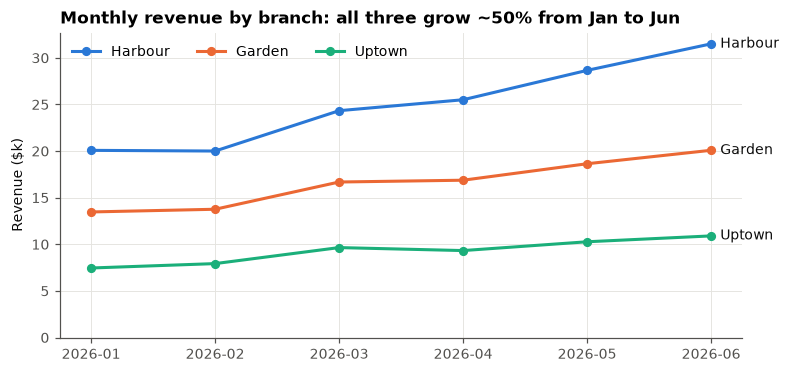

Jan->Jun growth:
branch
Harbour    0.569
Garden     0.491
Uptown     0.462
Jan->Jun growth, all: 0.524


In [8]:
m = df.groupby(["month", "branch"]).rev.sum().unstack()[BRANCHES]
fig, ax = plt.subplots(figsize=(8, 3.6))
for b in BRANCHES:
    ax.plot(m.index, m[b] / 1000, color=BRANCH_COLORS[b], marker="o", ms=5, label=b)
    ax.annotate(b, (m.index[-1], m[b].iloc[-1] / 1000), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=9)
ax.set_ylabel("Revenue ($k)"); ax.set_ylim(0)
ax.set_title("Monthly revenue by branch: all three grow ~50% from Jan to Jun")
ax.legend(loc="upper left", ncols=3); save(fig, "01_monthly_revenue"); plt.show()
g = (m.iloc[-1] / m.iloc[0] - 1).round(3); print("Jan->Jun growth:"); print(g.to_string())
print("Jan->Jun growth, all:", round(m.sum(1).iloc[-1] / m.sum(1).iloc[0] - 1, 3))

In [9]:
# Is growth from more transactions or bigger tickets?
mt = tx.groupby("month").agg(txns=("rev", "size"), avg_ticket=("rev", "mean"), items=("items", "mean"))
mt["txns_per_day"] = mt.txns / df.groupby("month").date.nunique()
mt.round(2)

,txns,avg_ticket,items,txns_per_day
month,,,,
2026-01,4545,9.02,1.59,146.61
2026-02,4619,9.03,1.60,164.96
2026-03,5628,9.00,1.60,181.55
2026-04,5750,8.99,1.59,191.67
2026-05,6439,8.94,1.59,207.71
2026-06,6906,9.05,1.59,230.20


**Observed:** growth comes from more transactions per day. Ticket size and items per basket stay flat, so the business is gaining traffic, not upselling.

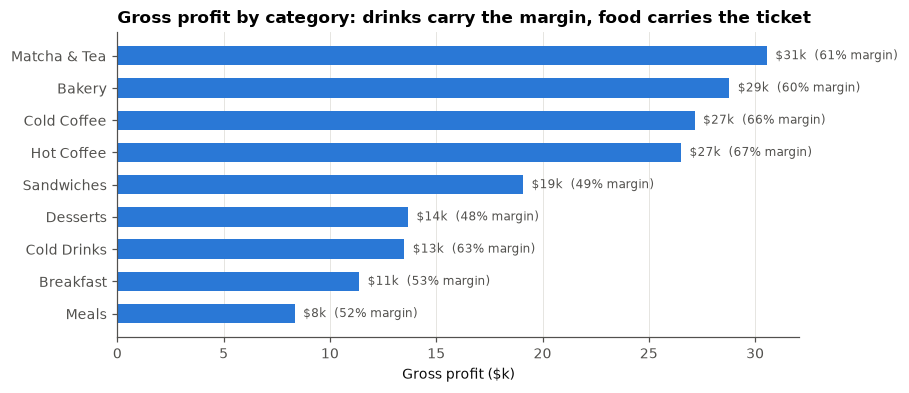

,rev,gp,qty,margin
category,,,,
Matcha & Tea,50160.03,30554.71,7977,0.609
Bakery,47874.27,28790.12,11645,0.601
Cold Coffee,41059.42,27154.19,7722,0.661
Hot Coffee,39788.15,26518.86,8581,0.667
Sandwiches,38814.96,19087.26,3899,0.492
Desserts,28676.00,13672.72,4675,0.477
Cold Drinks,21342.05,13498.68,5481,0.632
Breakfast,21364.71,11377.20,2472,0.533
Meals,16104.12,8340.54,1503,0.518


In [10]:
cat = df.groupby("category").agg(rev=("rev", "sum"), gp=("gp", "sum"), qty=("qty", "sum"))
cat["margin"] = cat.gp / cat.rev
cat = cat.sort_values("gp")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(cat.index, cat.gp / 1000, color="#2a78d6", height=0.6)
for i, (v, mg) in enumerate(zip(cat.gp / 1000, cat.margin)):
    ax.text(v + 0.4, i, f"${v:.0f}k  ({mg:.0%} margin)", va="center", color=MUTED, fontsize=8)
ax.set_xlabel("Gross profit ($k)"); ax.grid(axis="y", visible=False)
ax.set_title("Gross profit by category: drinks carry the margin, food carries the ticket")
save(fig, "02_category_gp"); plt.show()
cat.sort_values("gp", ascending=False).round(3)

In [11]:
prod = df.groupby(["product", "category"]).agg(rev=("rev", "sum"), gp=("gp", "sum"), qty=("qty", "sum")).reset_index()
prod["margin"] = prod.gp / prod.rev
prod = prod.sort_values("gp", ascending=False)
prod["cum_gp_share"] = prod.gp.cumsum() / prod.gp.sum()
print("products needed for 50% / 80% of gross profit:",
      (prod.cum_gp_share < 0.5).sum() + 1, "/", (prod.cum_gp_share < 0.8).sum() + 1, "of", len(prod))
prod.round(2).head(10)

products needed for 50% / 80% of gross profit: 16 / 30 of 45


,product,category,rev,gp,qty,margin,cum_gp_share
29,Iced Matcha,Matcha & Tea,16017.88,9426.94,2314,0.59,0.05
28,Iced Latte,Cold Coffee,14067.95,9179.05,2617,0.65,0.10
16,Classic Matcha,Matcha & Tea,12758.68,7712.79,1956,0.60,0.15
40,Strawberry Matcha,Matcha & Tea,11456.13,6128.09,1481,0.53,0.18
18,Cold Brew,Cold Coffee,7746.07,5795.73,1494,0.75,0.21
11,Chicken Pesto Sandwich,Sandwiches,12373.23,5733.55,1145,0.46,0.25
6,Butter Croissant,Bakery,8241.42,5383.66,2230,0.65,0.28
26,Halloumi Wrap,Sandwiches,9669.32,5203.44,967,0.54,0.30
44,Vanilla Latte,Hot Coffee,7683.75,4962.75,1394,0.65,0.33
7,Cappuccino,Hot Coffee,6873.91,4760.31,1678,0.69,0.36


**Observed:** profit is spread out. It takes 16 of 45 products to make half the gross profit, so there is no single hero product to protect or one dead SKU to cut. Drinks run at 65 to 82% margin. Sandwiches, meals, and desserts run at 45 to 55%.

## 3. Branch economics

Garden's margin stood out in the first pass. This section checks whether that comes from product mix, pricing, or cost.

In [12]:
br = df.groupby("branch").agg(rev=("rev", "sum"), gp=("gp", "sum"), lines=("rev", "size")).loc[BRANCHES]
br["margin"] = br.gp / br.rev
br["txns"] = tx.groupby("branch").size()
br["avg_ticket"] = tx.groupby("branch").rev.mean()
br.round(3)

,rev,gp,lines,margin,txns,avg_ticket
branch,,,,,,
Harbour,150099.05,97503.46,24586,0.650,16334,9.189
Garden,99530.55,46696.16,16869,0.469,11163,8.916
Uptown,55554.11,34794.66,9590,0.626,6390,8.694


In [13]:
# Price and cost of each product relative to Harbour
pc = df.groupby(["product", "branch"])[["price", "cost"]].first().unstack()
idx = pd.DataFrame({
    "price_vs_H_Garden": pc["price"]["Garden"] / pc["price"]["Harbour"],
    "price_vs_H_Uptown": pc["price"]["Uptown"] / pc["price"]["Harbour"],
    "cost_vs_H_Garden": pc["cost"]["Garden"] / pc["cost"]["Harbour"],
    "cost_vs_H_Uptown": pc["cost"]["Uptown"] / pc["cost"]["Harbour"],
})
print(idx.describe().loc[["mean", "min", "max", "std"]].round(3))

      price_vs_H_Garden  price_vs_H_Uptown  cost_vs_H_Garden  cost_vs_H_Uptown
mean              0.952              0.914             1.430             0.960
min               0.951              0.912             1.426             0.952
max               0.953              0.916             1.439             0.965
std               0.001              0.001             0.002             0.003


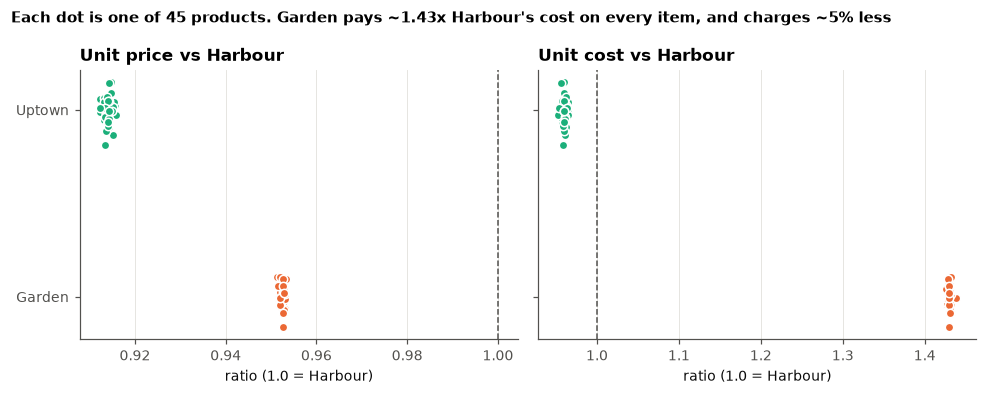

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, what, title in [(axes[0], "price", "Unit price vs Harbour"), (axes[1], "cost", "Unit cost vs Harbour")]:
    for j, b in enumerate(["Garden", "Uptown"]):
        r = pc[what][b] / pc[what]["Harbour"]
        ax.scatter(r, np.random.default_rng(j).normal(j, 0.07, len(r)), s=30, color=BRANCH_COLORS[b],
                   edgecolor="white", linewidth=1, label=b)
    ax.axvline(1, color=MUTED, lw=1, ls="--")
    ax.set_yticks([0, 1], ["Garden", "Uptown"]); ax.set_title(title); ax.set_xlabel("ratio (1.0 = Harbour)")
    ax.grid(axis="y", visible=False)
fig.suptitle("Each dot is one of 45 products. Garden pays ~1.43x Harbour's cost on every item, and charges ~5% less",
             x=0.01, ha="left", fontsize=10, fontweight="bold")
fig.tight_layout(); save(fig, "03_price_cost_index"); plt.show()

**Observed:** this is not a mix effect. On **every one of the 45 products**, Garden's recorded unit cost is a near-constant multiple of Harbour's (about 1.43x), while its menu price is about 5% *lower*. Uptown is the cheapest on cost and also prices slightly below Harbour.

A gap this uniform across product types (coffee, juice, sandwiches, pastries) points to something branch-wide, such as the supplier, the cost-allocation rule, or waste and overhead loaded into the standard cost. It does not point to individual ingredients.

In [15]:
# Decompose Garden's margin gap vs Harbour, holding Garden's actual volumes and discounts fixed
g = df[df.branch == "Garden"].copy()
hp = pc["price"]["Harbour"]; hc = pc["cost"]["Harbour"]; up_c = pc["cost"]["Uptown"]
g["rev_Hprice"] = g.qty * g["product"].map(hp) * (1 - g.disc)
g["cost_actual"] = g.qty * g.cost
g["cost_H"] = g.qty * g["product"].map(hc)
g["cost_U"] = g.qty * g["product"].map(up_c)

actual_gp = g.gp.sum()
cost_effect = (g.cost_actual - g.cost_H).sum()
price_effect = (g.rev_Hprice - g.rev).sum()
gp_at_H = (g.rev_Hprice - g.cost_H).sum()
mix_margin = gp_at_H / g.rev_Hprice.sum()
H_margin = br.loc["Harbour", "margin"]
print(f"Garden actual GP (6 mo):                       ${actual_gp:,.0f}  margin {actual_gp/g.rev.sum():.1%}")
print(f"Cost effect  (Garden cost -> Harbour cost):    +${cost_effect:,.0f}")
print(f"  (or Garden cost -> Uptown cost):             +${(g.cost_actual - g.cost_U).sum():,.0f}")
print(f"Price effect (Garden price -> Harbour price):  +${price_effect:,.0f}  (at unchanged volume)")
print(f"Garden margin at Harbour prices & costs: {mix_margin:.1%} vs Harbour actual {H_margin:.1%}  -> mix explains {H_margin-mix_margin:.1%} pts")
print(f"Estimate, annualised: cost gap ~${2*cost_effect:,.0f}/yr, price gap ~${2*price_effect:,.0f}/yr (before any volume response)")

Garden actual GP (6 mo):                       $46,696  margin 46.9%
Cost effect  (Garden cost -> Harbour cost):    +$15,888
  (or Garden cost -> Uptown cost):             +$17,370
Price effect (Garden price -> Harbour price):  +$4,974  (at unchanged volume)
Garden margin at Harbour prices & costs: 64.6% vs Harbour actual 65.0%  -> mix explains 0.3% pts
Estimate, annualised: cost gap ~$31,775/yr, price gap ~$9,948/yr (before any volume response)


**Observed:** at Harbour's costs and prices, Garden's margin would be essentially the same as Harbour's. Product mix explains almost none of the gap. Almost all of it is the **unit cost** line, with a smaller **price** component.

*Estimate (not measured):* if Garden's unit costs matched Harbour's, gross profit would be about $15k higher per half year, or about $30k per year. Matching Harbour's prices adds a smaller amount, but only if volume does not fall, and this data cannot test price elasticity because prices never change.

**Alternative explanations to test before acting** (the data cannot separate these):
1. **Different supplier or contract at Garden.** This is actionable through procurement.
2. **Cost-allocation artifact.** Garden's standard cost may include rent, labour, or waste that the other branches book elsewhere. If so, the gap is an accounting choice, not real money.
3. **Higher waste or larger portions at Garden,** baked into the standard cost.
4. **Scale.** Not supported: Uptown is the *smallest* branch and has the *lowest* costs.

In [16]:
# Does the gap move over time? (unit cost is fixed, so check realised cost per $ revenue by month)
cm = df.groupby(["month", "branch"]).apply(lambda x: x.gp.sum() / x.rev.sum(), include_groups=False).unstack()[BRANCHES]
cm.round(3)

branch,Harbour,Garden,Uptown
month,,,
2026-01,0.649,0.469,0.627
2026-02,0.653,0.467,0.625
2026-03,0.649,0.472,0.628
2026-04,0.650,0.467,0.626
2026-05,0.648,0.472,0.624
2026-06,0.649,0.468,0.628


**Observed:** each branch's margin is flat month to month, so the gap is structural. It has been present since January and is not getting worse.

## 4. When do customers buy?

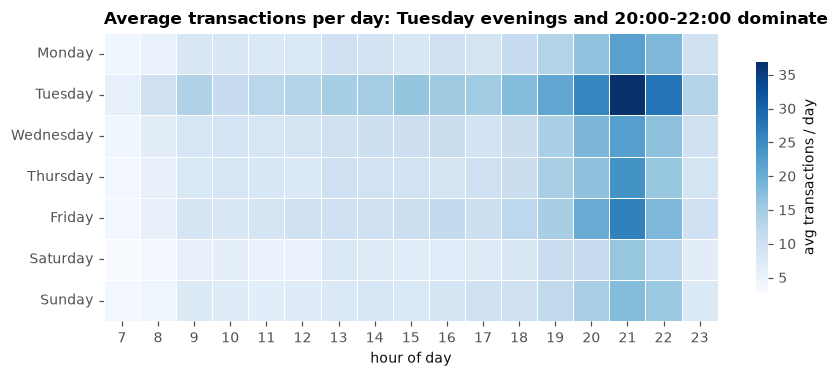

In [17]:
# Average transactions per calendar day, by weekday and hour (normalises for the number of Mondays etc.)
n_days = tx.groupby("dow").date.nunique()
heat = tx.groupby(["dow", "hour"]).size().unstack().div(n_days, axis=0).loc[DOW]
fig, ax = plt.subplots(figsize=(9, 3.4))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "avg transactions / day", "shrink": 0.8},
            linewidths=0.5, linecolor="white")
ax.set_xlabel("hour of day"); ax.set_ylabel("")
ax.set_title("Average transactions per day: Tuesday evenings and 20:00-22:00 dominate")
save(fig, "04_dow_hour_heatmap"); plt.show()

In [18]:
daily = tx.groupby(["date", "branch"]).size().unstack()[BRANCHES]
daily["dow"] = daily.index.day_name()
per_dow = daily.groupby("dow")[BRANCHES].mean().loc[DOW]
print("avg transactions per day by weekday:"); print(per_dow.round(1))
print("\nTuesday index vs mean of other weekdays:")
print((per_dow.loc["Tuesday"] / per_dow.drop("Tuesday").mean()).round(2).to_string())

avg transactions per day by weekday:
branch     Harbour  Garden  Uptown
dow                               
Monday        84.7    59.7    33.6
Tuesday      136.7    94.7    53.2
Wednesday     91.3    60.5    34.4
Thursday      86.4    58.7    34.9
Friday        96.0    64.4    37.1
Saturday      61.6    42.7    24.5
Sunday        75.2    51.1    29.4

Tuesday index vs mean of other weekdays:
branch
Harbour    1.66
Garden     1.69
Uptown     1.64


In [19]:
# Does the Tuesday spike hold every week? Compare each Tuesday with the other 6 days of its week
d_all = tx.groupby("date").size().to_frame("n")
d_all["week"] = d_all.index.to_period("W-SUN"); d_all["dow"] = d_all.index.day_name()
wk = d_all.groupby("week").apply(lambda w: w.loc[w.dow == "Tuesday", "n"].sum() / w.loc[w.dow != "Tuesday", "n"].mean()
                                  if (w.dow == "Tuesday").any() and len(w) == 7 else np.nan, include_groups=False).dropna()
print(f"full weeks: {len(wk)} | Tuesday is busiest day in {(d_all.groupby('week').apply(lambda w: w.n.idxmax().day_name() == 'Tuesday' if len(w)==7 else np.nan, include_groups=False).dropna()).mean():.0%} of them")
print("Tuesday / other-day ratio per week: min", wk.min().round(2), "median", wk.median().round(2), "max", wk.max().round(2))

# Is the extra Tuesday volume more customers, bigger baskets, or one category?
t_cmp = tx.assign(tue=tx.dow == "Tuesday").groupby("tue").agg(
    avg_ticket=("rev", "mean"), items=("items", "mean"), disc_share=("any_disc", lambda s: (s > 0).mean()),
    known_share=("cust", lambda s: s.notna().mean()), takeaway=("order_type", lambda s: (s == "Takeaway").mean()))
print(t_cmp.round(3))
cat_mix = df.assign(tue=df.dow == "Tuesday").groupby(["tue", "category"]).qty.sum().unstack(0)
print("\ncategory share, Tuesday vs other days:"); print((cat_mix / cat_mix.sum()).round(3))

full weeks: 25 | Tuesday is busiest day in 100% of them
Tuesday / other-day ratio per week: min 1.44 median 1.61 max 1.81
       avg_ticket  items  disc_share  known_share  takeaway
tue                                                        
False       9.005  1.593       0.094        0.634     0.407
True        9.010  1.588       0.101        0.642     0.417

category share, Tuesday vs other days:
tue           False  True 
category                  
Bakery        0.216  0.215
Breakfast     0.046  0.044
Cold Coffee   0.144  0.138
Cold Drinks   0.101  0.102
Desserts      0.086  0.087
Hot Coffee    0.158  0.163
Matcha & Tea  0.147  0.150
Meals         0.028  0.029
Sandwiches    0.073  0.071


**Observed:** Tuesday has about 1.6x the transactions of an average other day at **all three branches** and and Tuesday is the busiest day in every one of the 25 full weeks (Tuesday/other-day ratio 1.44 to 1.81). Baskets, discount rate, category mix, and the share of identified customers on Tuesday look the same as on other days. So Tuesday brings *more of the same customers*, not a different kind of visit.

*Assumption:* the dataset has no promotion calendar. A recurring Tuesday promotion (one not recorded as a line discount), a local event, or a pattern in the data generator could each explain this. **Stories should confirm the cause before staffing around it.** If it is a promotion, its cost is invisible in this file.

Saturday is the weakest day. 45% of revenue arrives between 19:00 and midnight, against 18% before noon. In the evening the mix shifts toward matcha, cold coffee and desserts, and away from hot coffee and breakfast. A café with a Saturday trough and a late-evening peak looks like an evening social venue, not a commuter morning café.

In [20]:
hr = tx.groupby("hour").agg(txns=("rev", "size"), rev=("rev", "sum"))
hr["share"] = hr.rev / hr.rev.sum()
print(f"revenue share 19:00-23:59: {hr.loc[19:23, 'share'].sum():.1%} | 07:00-11:59: {hr.loc[7:11, 'share'].sum():.1%}")
cat_hr = df.groupby(["hour", "category"]).rev.sum().unstack()
(cat_hr.div(cat_hr.sum(1), axis=0).loc[[8, 12, 16, 21]]).round(2)

revenue share 19:00-23:59: 44.7% | 07:00-11:59: 17.9%


category,Bakery,Breakfast,Cold Coffee,Cold Drinks,Desserts,Hot Coffee,Matcha & Tea,Meals,Sandwiches
hour,,,,,,,,,
8,0.20,0.10,0.10,0.07,0.05,0.19,0.14,0.03,0.12
12,0.16,0.07,0.12,0.07,0.08,0.15,0.15,0.05,0.13
16,0.16,0.08,0.11,0.08,0.09,0.15,0.13,0.05,0.15
21,0.15,0.04,0.16,0.07,0.13,0.09,0.19,0.05,0.12


## 5. Baskets

In [21]:
print("items per transaction:"); print(tx["items"].value_counts(normalize=True).sort_index().round(3).to_string())
print("\navg ticket by branch and order type:")
print(tx.pivot_table(index="branch", columns="order_type", values="rev", aggfunc="mean").loc[BRANCHES].round(2))

items per transaction:
items
1    0.508
2    0.401
3    0.083
4    0.008
5    0.000

avg ticket by branch and order type:
order_type  Dine-in  Takeaway
branch                       
Harbour        9.18      9.20
Garden         8.92      8.92
Uptown         8.75      8.61


In [22]:
# Attach rate: of transactions containing a drink, how many also include food?
DRINK = {"Hot Coffee", "Cold Coffee", "Matcha & Tea", "Cold Drinks"}
cats = df.groupby("txn").category.agg(set)
has_drink = cats.apply(lambda s: bool(s & DRINK)); has_food = cats.apply(lambda s: bool(s - DRINK))
print(f"drink-only txns: {(has_drink & ~has_food).mean():.1%} | food-only: {(~has_drink & has_food).mean():.1%} | both: {(has_drink & has_food).mean():.1%}")
att = pd.DataFrame({"drink": has_drink, "food": has_food}).join(tx[["branch", "hour"]])
att = att[att.drink]
print("\nfood attach rate among drink transactions, by branch:"); print(att.groupby("branch").food.mean().loc[BRANCHES].round(3).to_string())
print("\nby hour:"); print(att.groupby("hour").food.mean().round(2).to_string())

drink-only txns: 40.9% | food-only: 30.9% | both: 28.2%

food attach rate among drink transactions, by branch:
branch
Harbour    0.402
Garden     0.418
Uptown     0.409

by hour:
hour
7     0.39
8     0.39
9     0.42
10    0.41
11    0.40
12    0.40
13    0.42
14    0.41
15    0.42
16    0.43
17    0.40
18    0.42
19    0.41
20    0.41
21    0.40
22    0.40
23    0.40


In [23]:
# Most common product pairs in the same basket
from itertools import combinations
from collections import Counter
pairs = Counter()
for items in df.groupby("txn")["product"].agg(lambda s: sorted(set(s))):
    pairs.update(combinations(items, 2))
pd.DataFrame(pairs.most_common(10), columns=["pair", "baskets"])

,pair,baskets
0,"(Butter Croissant, Iced Matcha)",114
1,"(Butter Croissant, Classic Matcha)",103
2,"(Butter Croissant, Iced Latte)",93
3,"(Chocolate Cookie, Iced Matcha)",89
4,"(Chocolate Croissant, Iced Matcha)",89
5,"(Iced Matcha, Pistachio Cookie)",82
6,"(Chocolate Cookie, Classic Matcha)",76
7,"(Cinnamon Roll, Classic Matcha)",76
8,"(Chocolate Croissant, Classic Matcha)",74
9,"(Cinnamon Roll, Iced Matcha)",73


**Observed:** most baskets have 1 or 2 items. The food attach rate on drink orders is the main lever for ticket size. It is similar across branches and hours, and no product pair stands out. Pairs look close to independent, so any cross-sell result would need a controlled test, not a basket-rule mining exercise.

## 6. Customers (identified customers only)

In [24]:
k = tx[tx.cust.notna()]
vis = k.groupby("cust").size()
print("visits per customer over 6 months:"); print(vis.describe().round(2).to_string())
first = k.groupby("cust").month.min().value_counts().sort_index()
active = k.groupby("month").cust.nunique()
cust_m = pd.DataFrame({"new": first, "active": active}).fillna(0).astype(int)
cust_m["returning"] = cust_m.active - cust_m.new
cust_m

visits per customer over 6 months:
count    3494.00
mean        6.16
std         2.47
min         1.00
25%         4.00
50%         6.00
75%         8.00
max        18.00


,new,active,returning
month,,,
2026-01,1979,1979,0
2026-02,843,1965,1122
2026-03,433,2233,1800
2026-04,159,2283,2124
2026-05,60,2435,2375
2026-06,20,2525,2505


**Observed:** new identified customers fall from about 1,980 in January to about 20 in June, while active customers rise. Most of this is a **left-censoring artifact**: the data starts on 1 January, so everyone counts as "new" the first time they appear. With a base of ~3,500 people visiting about once a month, almost all of them show up within the first quarter.

It does mean the identified base is *closed*. Hardly anyone joins after March. So the revenue growth comes from anonymous customers and from more frequent visits by the existing base.

In [25]:
# Revenue growth: identified vs anonymous
kx = tx.assign(known=tx.cust.notna()).groupby(["month", "known"]).rev.sum().unstack()
kx.columns = ["anonymous", "identified"]; kx["identified_share"] = kx.identified / kx.sum(1)
kx.round(3)

,anonymous,identified,identified_share
month,,,
2026-01,14994.74,26019.87,0.634
2026-02,15040.85,26662.07,0.639
2026-03,18690.46,31980.15,0.631
2026-04,18778.94,32938.55,0.637
2026-05,21293.81,36285.57,0.630
2026-06,22656.72,39841.98,0.637


In [26]:
# Cross-branch behaviour: is it consistent with customers choosing a branch at random?
share = tx.groupby("branch").size() / len(tx)
obs = k.groupby("cust").branch.nunique()
n = vis.loc[obs.index]
# expected P(only one branch) given n visits if each visit picks a branch independently by overall share
p_one = sum(share[b] ** n for b in share.index)
print(f"observed share of customers seen at >1 branch: {(obs > 1).mean():.1%}")
print(f"expected if branch choice were random:         {(1 - p_one).mean():.1%}")
home = k.groupby("cust").branch.agg(lambda s: s.value_counts(normalize=True).iloc[0])
rng = np.random.default_rng(0)
sim_home = [np.bincount(rng.choice(3, size=v, p=share.values), minlength=3).max() / v for v in n]
print(f"avg share of a customer's visits at their most-used branch: observed {home.mean():.1%} vs random-choice simulation {np.mean(sim_home):.1%}")

observed share of customers seen at >1 branch: 93.8%
expected if branch choice were random:         94.1%


avg share of a customer's visits at their most-used branch: observed 59.5% vs random-choice simulation 59.1%


**Observed:** customers spread their visits across branches almost exactly as random branch choice would predict. Real customers usually have a 'home' branch. *Assumption:* the replacement customer IDs (or the data generation) do not preserve real customer-branch loyalty. **Customer-level findings (retention, churn, loyalty value) are therefore weak evidence in this file**, and we will not build the headline on them.

## 7. Discounts

In [27]:
print(f"discounted lines: {(df.disc > 0).mean():.1%} | $ given away: ${df.disc_usd.sum():,.0f} ({df.disc_usd.sum()/df.gross.sum():.2%} of list revenue)")
# Applied per line or per basket?
mixed = df.groupby("txn").disc.agg(lambda s: s.nunique() > 1)
print(f"txns with a mix of discounted and full-price lines: {mixed.mean():.1%} of all txns, "
      f"{mixed.sum() / (tx.any_disc > 0).sum():.0%} of discounted txns")
for col in ["branch", "category", "order_type", "dow"]:
    print(f"\ndiscounted line share by {col}:"); print(df.groupby(col).disc.apply(lambda s: (s > 0).mean()).round(3).to_string())

discounted lines: 6.6% | $ given away: $2,176 (0.71% of list revenue)


txns with a mix of discounted and full-price lines: 5.8% of all txns, 60% of discounted txns

discounted line share by branch:
branch
Garden     0.055
Harbour    0.076
Uptown     0.058

discounted line share by category:
category
Bakery          0.054
Breakfast       0.057
Cold Coffee     0.101
Cold Drinks     0.057
Desserts        0.095
Hot Coffee      0.059
Matcha & Tea    0.058
Meals           0.042
Sandwiches      0.055

discounted line share by order_type:
order_type
Dine-in     0.067
Takeaway    0.064

discounted line share by dow:
dow
Friday       0.068
Monday       0.062
Saturday     0.064
Sunday       0.065
Thursday     0.067
Tuesday      0.070
Wednesday    0.062


In [28]:
print("discount share by hour:"); print(df.groupby("hour").disc.apply(lambda s: (s > 0).mean()).round(3).to_string())
print("\nidentified vs anonymous:"); print(df.groupby("known").disc.apply(lambda s: (s > 0).mean()).round(3).to_string())

discount share by hour:
hour
7     0.061
8     0.062
9     0.061
10    0.061
11    0.065
12    0.063
13    0.058
14    0.065
15    0.063
16    0.064
17    0.067
18    0.069
19    0.073
20    0.069
21    0.069
22    0.066
23    0.067

identified vs anonymous:
known
False    0.066
True     0.066


In [29]:
# Basket comparison: discounted vs not (correlation only)
b = tx.assign(discounted=tx.any_disc > 0).groupby("discounted").agg(
    txns=("rev", "size"), items=("items", "mean"), ticket=("rev", "mean"), gp=("gp", "mean"))
b.round(2)

,txns,items,ticket,gp
discounted,,,,
False,30640,1.57,8.94,5.26
True,3247,1.81,9.60,5.48


**Observed:** discounts are applied to individual lines, not whole baskets, and most discounted baskets also contain full-price items. Cold Coffee and Desserts are discounted about twice as often as other categories. Discounted baskets are larger, but that is **correlation, not proof that discounts cause bigger baskets**. Bigger baskets have more lines, so they simply have more chances to contain a discounted line.

The direct cost is small: $2,176, or 0.7% of list revenue. *Estimate:* this is not a large lever unless Stories also runs untracked promotions (see Tuesday).

## 8. Candidate problems, ranked

In [30]:
cands = pd.DataFrame([
    ["Garden unit cost ~1.43x other branches on every product", f"~${2*cost_effect:,.0f}/yr GP (Estimate)", "Strong: uniform across all 45 products, flat for 6 months",
     "Supplier contract; cost-allocation rule; waste/portion", "How Garden's standard cost is built; invoices"],
    ["Garden prices ~5% below Harbour", f"up to ~${2*price_effect:,.0f}/yr (Estimate, ignores volume loss)", "Strong fact, unknown elasticity",
     "Deliberate local pricing for a price-sensitive area", "Any price change history; competitor prices"],
    ["Tuesday demand ~1.6x other days; evening peak", "Staffing/prep efficiency (needs labour data)", "Strong pattern, cause unknown",
     "Untracked promotion; event; data artifact", "Promo calendar, staff rota, labour cost"],
    ["Duplicate POS rows (0.26%)", f"~${2*dups.rev.sum():,.0f}/yr of revenue overstated", "Strong",
     "Real repeat scans", "POS logs"],
    ["Food attach on drink orders", "Ticket size lever", "Medium: needs a controlled test", "-", "Experiment"],
    ["Customer retention / loyalty", "Unclear", "Weak: IDs behave like random branch choice", "ID replacement artifact", "Real loyalty IDs"],
    ["Discount policy", f"~${2*df.disc_usd.sum():,.0f}/yr given away", "Weak causal evidence", "Selection: big baskets get discounts", "Discount reason codes"],
], columns=["candidate", "value", "evidence", "alternative explanations", "missing data"])
cands

,candidate,value,evidence,alternative explanations,missing data
0,Garden unit cost ~1.43x other branches on ever...,"~$31,775/yr GP (Estimate)","Strong: uniform across all 45 products, flat f...",Supplier contract; cost-allocation rule; waste...,How Garden's standard cost is built; invoices
1,Garden prices ~5% below Harbour,"up to ~$9,948/yr (Estimate, ignores volume loss)","Strong fact, unknown elasticity",Deliberate local pricing for a price-sensitive...,Any price change history; competitor prices
2,Tuesday demand ~1.6x other days; evening peak,Staffing/prep efficiency (needs labour data),"Strong pattern, cause unknown",Untracked promotion; event; data artifact,"Promo calendar, staff rota, labour cost"
3,Duplicate POS rows (0.26%),"~$1,483/yr of revenue overstated",Strong,Real repeat scans,POS logs
4,Food attach on drink orders,Ticket size lever,Medium: needs a controlled test,-,Experiment
5,Customer retention / loyalty,Unclear,Weak: IDs behave like random branch choice,ID replacement artifact,Real loyalty IDs
6,Discount policy,"~$4,352/yr given away",Weak causal evidence,Selection: big baskets get discounts,Discount reason codes


### Takeaways

1. **Data quality is good.** The money columns reconcile exactly. There are 132 duplicate rows, which we removed. Prices and costs are fixed for the whole period.
2. **The largest and best-evidenced problem is Garden's unit-cost structure.** It is worth about $30k of gross profit per year if it is real money and not an allocation choice. The first action is cheap: ask finance how Garden's standard cost is built and compare supplier invoices. This is the recommended headline for the next notebook.
3. **Tuesday and the evening peak** are strong operational patterns. They are worth a secondary section and a demand forecast compared against a seasonal-naive baseline, but the value can't be sized without labour data.
4. **Customer-level and discount findings are weak** in this dataset. We will report them as limitations, not recommendations.